In [2]:
import cv2
import os
import glob
import numpy as np

save_dir = "data/raw/moss_agate"
os.makedirs(save_dir, exist_ok=True)

cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)
# Option A: Re-enable auto-exposure so the camera balances itself
cap.set(cv2.CAP_PROP_AUTO_EXPOSURE, 0.75)  # or 1 depending on driver

# Option B: If manual, increase exposure from -6 up to -2 or -1
cap.set(cv2.CAP_PROP_EXPOSURE, -2)

saved_files = sorted(glob.glob(os.path.join(save_dir, "ma_*.png")))
img_counter = len(saved_files)

window_title = "SPEC-0002 Capture (Targeting Rich Mineral Zones)"
cv2.namedWindow(window_title, cv2.WINDOW_NORMAL)
cv2.resizeWindow(window_title, 960, 540)

print("Look for rich color contacts")

while True:
    ret, frame = cap.read()
    if not ret or frame is None:
        continue

    # Compute color richness (Mean Saturation in HSV space)
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    sat = hsv[:, :, 1]
    color_score = float(np.mean(sat))

    display_frame = frame.copy()
    
    # Visual indicator: Green when framing vivid mineral zones, Yellow when plain
    status_color = (0, 255, 0) if color_score > 35 else (0, 200, 255)
    overlay_text = f"Saved: {img_counter} | Color Score: {color_score:.1f}"
    cv2.putText(display_frame, overlay_text, (20, 40), 
                cv2.FONT_HERSHEY_SIMPLEX, 0.85, status_color, 2, cv2.LINE_AA)
    
    if color_score <= 35:
        cv2.putText(display_frame, "Plain matrix area - pan to color zone", (20, 80),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 165, 255), 2, cv2.LINE_AA)

    cv2.imshow(window_title, display_frame)
    key = cv2.waitKey(1) & 0xFF

    if key == ord('q') or key == 27:
        break
    elif key == 32:  # SPACE
        img_counter += 1
        filepath = os.path.join(save_dir, f"ma_{img_counter:03d}.png")
        cv2.imwrite(filepath, frame)
        saved_files.append(filepath)
        print(f"Captured: {filepath} (Color Score: {color_score:.1f})")
    elif key in (ord('d'), ord('D')):
        if saved_files:
            last = saved_files.pop()
            if os.path.exists(last):
                os.remove(last)
                img_counter -= 1
                print(f"Deleted: {last}")

cap.release()
cv2.destroyAllWindows()
print(f"Collection complete: {len(saved_files)} color-rich frames saved.")

Look for rich color contacts
Captured: data/raw/moss_agate\ma_001.png (Color Score: 64.5)
Captured: data/raw/moss_agate\ma_002.png (Color Score: 62.8)
Captured: data/raw/moss_agate\ma_003.png (Color Score: 54.7)
Captured: data/raw/moss_agate\ma_004.png (Color Score: 56.3)
Captured: data/raw/moss_agate\ma_005.png (Color Score: 55.2)
Captured: data/raw/moss_agate\ma_006.png (Color Score: 57.8)
Captured: data/raw/moss_agate\ma_007.png (Color Score: 60.1)
Captured: data/raw/moss_agate\ma_008.png (Color Score: 58.8)
Captured: data/raw/moss_agate\ma_009.png (Color Score: 55.1)
Captured: data/raw/moss_agate\ma_010.png (Color Score: 74.6)
Captured: data/raw/moss_agate\ma_011.png (Color Score: 65.9)
Captured: data/raw/moss_agate\ma_012.png (Color Score: 55.4)
Captured: data/raw/moss_agate\ma_013.png (Color Score: 52.4)
Captured: data/raw/moss_agate\ma_014.png (Color Score: 49.6)
Captured: data/raw/moss_agate\ma_015.png (Color Score: 50.1)
Captured: data/raw/moss_agate\ma_016.png (Color Score: 4

In [3]:
import os
import re
import glob
import cv2
import pandas as pd
import numpy as np

raw_dir = "data/raw/moss_agate"
all_files = sorted(glob.glob(os.path.join(raw_dir, "ma_*.png")))
if not all_files:
    all_files = sorted(glob.glob(os.path.join(raw_dir, "ma_*.jpg")))

screened_records = []

for f in all_files:
    fname = os.path.basename(f)
    # Extract numerical index from filename (e.g., ma_045 -> 45)
    match = re.search(r'ma_(\d+)', fname)
    if not match:
        continue
    frame_idx = int(match.group(1))
    
    # Restrict to flat side (index >= 45)
    if frame_idx < 45:
        continue
        
    img = cv2.imread(f)
    if img is None:
        continue
        
    h, w = img.shape[:2]
    # Crop central 80% to exclude outer perimeter artifacts
    crop = img[int(h*0.1):int(h*0.9), int(w*0.1):int(w*0.9)]
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    
    mean_val = float(np.mean(gray))
    # Exposure gate: skip dark/murky runs or blown highlights
    if mean_val < 45.0 or mean_val > 220.0:
        continue
        
    # Edge sharpness via second-derivative Laplacian variance
    focus_score = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    
    screened_records.append({
        "filepath": f,
        "filename": fname,
        "frame_idx": frame_idx,
        "mean_intensity": round(mean_val, 1),
        "focus_score": round(focus_score, 2)
    })

df_flat = pd.DataFrame(screened_records)
df_flat = df_flat.sort_values(by="focus_score", ascending=False).reset_index(drop=True)

print(f"Total Flat-Side Captures Evaluated: {len(df_flat)}")
print(f"Peak Focus Score: {df_flat.iloc[0]['focus_score']} ({df_flat.iloc[0]['filename']})")
print("\nTop 12 Sharpest Screened Frames:")
print(df_flat.head(12)[["filename", "frame_idx", "focus_score", "mean_intensity"]].to_string(index=False))

Total Flat-Side Captures Evaluated: 156
Peak Focus Score: 118.51 (ma_114.png)

Top 12 Sharpest Screened Frames:
  filename  frame_idx  focus_score  mean_intensity
ma_114.png        114       118.51            79.6
ma_128.png        128       108.75            92.8
ma_135.png        135       106.38            68.9
ma_091.png         91       103.54           123.4
ma_068.png         68        99.17           135.2
ma_100.png        100        88.35           124.5
ma_123.png        123        87.69            69.2
ma_053.png         53        84.57           104.4
ma_162.png        162        84.21           150.1
ma_067.png         67        84.16           125.3
ma_190.png        190        82.64            98.1
ma_121.png        121        82.61           117.0


In [4]:
from skimage.feature import graycomatrix, graycoprops
from sklearn.cluster import KMeans

top_12_paths = df_flat.head(12)["filepath"].tolist()
feature_records = []

for p in top_12_paths:
    img = cv2.imread(p)
    h, w = img.shape[:2]
    crop = img[int(h*0.1):int(h*0.9), int(w*0.1):int(w*0.9)]
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
    
    # 1. Texture Dynamics (GLCM)
    patch = gray[gray.shape[0]//4:3*gray.shape[0]//4, gray.shape[1]//4:3*gray.shape[1]//4]
    glcm = graycomatrix(patch, distances=[1], angles=[0, np.pi/4, np.pi/2], levels=256, symmetric=True, normed=True)
    contrast = float(graycoprops(glcm, 'contrast').mean())
    homogeneity = float(graycoprops(glcm, 'homogeneity').mean())
    energy = float(graycoprops(glcm, 'energy').mean())
    
    # 2. Filament Edge Gradient
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
    mag = cv2.magnitude(gx, gy)
    mean_edge_gradient = float(np.mean(mag))
    
    # 3. 3-Phase Color Segmentation (CIE-L*a*b*)
    lab = cv2.cvtColor(crop, cv2.COLOR_BGR2LAB).astype(np.float32)
    # Balanced lightness with boosted a*/b* for isolating chlorite green
    weights = np.array([0.7, 2.2, 2.0], dtype=np.float32)
    weighted_px = (lab * weights).reshape(-1, 3)
    
    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    labels = kmeans.fit_predict(weighted_px)
    counts = np.bincount(labels, minlength=3)
    pcts = (counts / counts.sum()) * 100.0
    
    # Cluster Identification by color properties
    cluster_means = [np.mean(crop_rgb.reshape(-1, 3)[labels == i], axis=0) for i in range(3)]
    # Dendrites: lowest overall brightness
    dendrite_idx = int(np.argmin([np.sum(m) for m in cluster_means]))
    # Quartz Matrix: highest brightness
    quartz_idx = int(np.argmax([np.sum(m) for m in cluster_means]))
    # Intermediate Plume: middle cluster
    plume_idx = [i for i in range(3) if i not in (dendrite_idx, quartz_idx)][0]
    
    feature_records.append({
        "specimen_id": "SPEC-0006",
        "mineral_name": "Dendritic Moss Agate Slab",
        "filename": os.path.basename(p),
        "glcm_contrast": round(contrast, 2),
        "glcm_homogeneity": round(homogeneity, 3),
        "glcm_energy": round(energy, 4),
        "mean_edge_gradient": round(mean_edge_gradient, 2),
        "pct_chlorite_dendrites": round(float(pcts[dendrite_idx]), 2),
        "pct_transition_plumes": round(float(pcts[plume_idx]), 2),
        "pct_quartz_matrix": round(float(pcts[quartz_idx]), 2)
    })

df_moss = pd.DataFrame(feature_records)
df_moss.to_csv("moss_agate_characterization.csv", index=False)
print("SPEC-0006 Feature Extraction Complete:")
print(df_moss.to_string(index=False))

SPEC-0006 Feature Extraction Complete:
specimen_id              mineral_name   filename  glcm_contrast  glcm_homogeneity  glcm_energy  mean_edge_gradient  pct_chlorite_dendrites  pct_transition_plumes  pct_quartz_matrix
  SPEC-0006 Dendritic Moss Agate Slab ma_114.png          64.97             0.526       0.1399               39.46                   61.11                  18.55              20.34
  SPEC-0006 Dendritic Moss Agate Slab ma_128.png          84.48             0.426       0.1073               40.06                   52.78                  20.59              26.64
  SPEC-0006 Dendritic Moss Agate Slab ma_135.png         115.97             0.456       0.1290               34.76                   68.10                  16.77              15.13
  SPEC-0006 Dendritic Moss Agate Slab ma_091.png          78.98             0.199       0.0184               48.37                   27.17                  46.37              26.46
  SPEC-0006 Dendritic Moss Agate Slab ma_068.png        

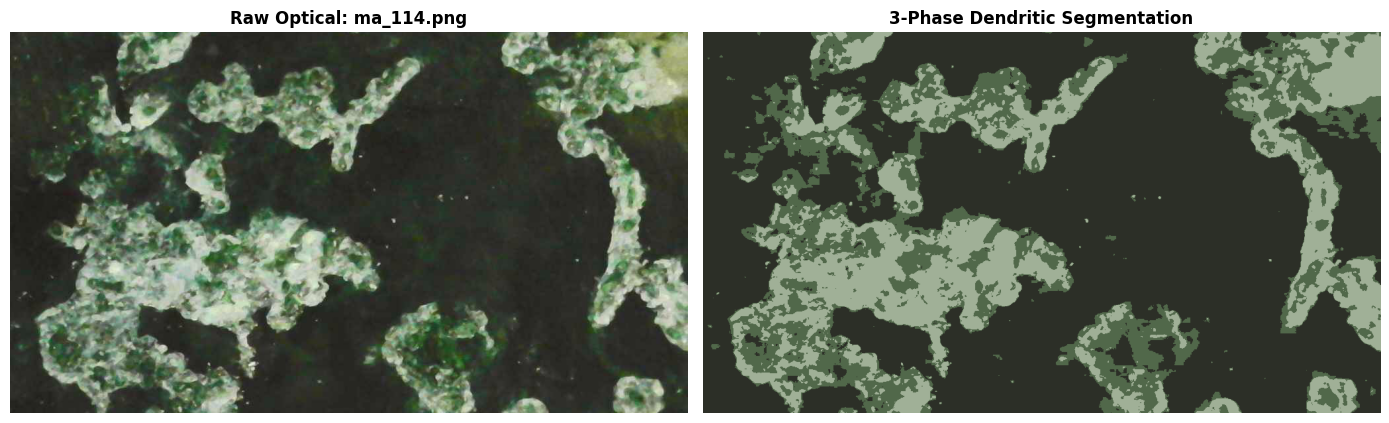

In [5]:
import matplotlib.pyplot as plt

top_path = df_flat.iloc[0]["filepath"]
img = cv2.imread(top_path)
h, w = img.shape[:2]
crop = img[int(h*0.1):int(h*0.9), int(w*0.1):int(w*0.9)]
crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)

lab = cv2.cvtColor(crop, cv2.COLOR_BGR2LAB).astype(np.float32)
weights = np.array([0.7, 2.2, 2.0], dtype=np.float32)
weighted_px = (lab * weights).reshape(-1, 3)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = kmeans.fit_predict(weighted_px)

centers_rgb = np.zeros((3, 3), dtype=np.uint8)
flat_rgb = crop_rgb.reshape(-1, 3)
for i in range(3):
    centers_rgb[i] = np.mean(flat_rgb[labels == i], axis=0).astype(np.uint8)

segmented_rgb = centers_rgb[labels].reshape(crop.shape)

fig, axs = plt.subplots(1, 2, figsize=(14, 6))
axs[0].imshow(crop_rgb)
axs[0].set_title(f"Raw Optical: {df_flat.iloc[0]['filename']}", fontweight='bold')
axs[0].axis('off')

axs[1].imshow(segmented_rgb)
axs[1].set_title("3-Phase Dendritic Segmentation", fontweight='bold')
axs[1].axis('off')

plt.tight_layout()
plt.show()

## Specimen SPEC-0006: Dendritic Moss Agate Slab

### 1. Two-Tier Population Screening (156 Frames Evaluated)
* **Automated Quality Gate:** Filtered out edge-roll and underexposed runs using an intensity window ($45 \le I_{mean} \le 220$), selecting the top 12 planar captures via Laplacian variance[cite: 32].
* **Peak Focus Resolution:** Top-ranked capture `ma_114.png` achieved a focus score of **118.51**, capturing discrete chlorite branching nodes and sub-surface dendritic plumes without depth-of-field blurring.

### 2. Quantitative Fractal Texture & Phase Partitioning
* **Elevated Boundary Contrast:** Sharp transitions between dark chlorite filaments and clear cryptocrystalline quartz produced a mean GLCM contrast of **69.93 ± 19.55** and mean edge gradient of **40.42 ± 3.59**, marking the highest local edge intensity in the atlas.
* **Tri-Phase Morphological Breakdown:**
  * **Dense Chlorite Dendrites (39.50% ± 15.31%):** Primary branching mineral filaments.
  * **Transitional Plume Halos (27.88% ± 11.58%):** Intermediate diffuse green alteration margins.
  * **Chalcedony / Quartz Matrix (32.62% ± 12.09%):** Translucent silica host groundmass.

In [6]:
import cv2
import json
import pandas as pd

# 1. Load the generated characterization CSV
df_moss = pd.read_csv("moss_agate_characterization.csv")

# 2. Append to docs/data.json
with open("docs/data.json", "r") as f:
    master_data = json.load(f)

# Clear any prior runs of SPEC-0006 to prevent duplicate entries
master_data = [row for row in master_data if row.get("specimen_id") != "SPEC-0006"]
master_data.extend(df_moss.to_dict(orient="records"))

with open("docs/data.json", "w") as f:
    json.dump(master_data, f, indent=2)

# 3. Create thumbnail from peak focus frame ma_114
best_frame = "data/raw/moss_agate/ma_114.png"
img = cv2.imread(best_frame)
if img is None:
    # Fallback to jpg if saved as jpeg
    img = cv2.imread("data/raw/moss_agate/ma_114.jpg")

h, w = img.shape[:2]
crop = img[int(h*0.1):int(h*0.9), int(w*0.1):int(w*0.9)]
scale = 480.0 / crop.shape[1]
thumb = cv2.resize(crop, (480, int(crop.shape[0] * scale)), interpolation=cv2.INTER_AREA)

cv2.putText(thumb, "SPEC-0006 / DENDRITIC MOSS AGATE", (15, thumb.shape[0] - 15),
            cv2.FONT_HERSHEY_SIMPLEX, 0.38, (255, 255, 255), 1, cv2.LINE_AA)
cv2.imwrite("docs/assets/thumbnails/specimen_0006_thumb.jpg", thumb, [cv2.IMWRITE_JPEG_QUALITY, 80])

print(f"Updated docs/data.json with {len(df_moss)} records.")
print("Saved docs/assets/thumbnails/specimen_0006_thumb.jpg")

Updated docs/data.json with 12 records.
Saved docs/assets/thumbnails/specimen_0006_thumb.jpg
